In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, log_loss

In [57]:
plt.style.use('dark_background')
np.random.seed(42)

california = fetch_california_housing()
X = np.column_stack([california.data, california.target])


In [58]:
feature_names = list(california.feature_names) + ['MedHouseVal']
feature_names

['MedInc',
 'HouseAge',
 'AveRooms',
 'AveBedrms',
 'Population',
 'AveOccup',
 'Latitude',
 'Longitude',
 'MedHouseVal']

In [59]:
# ndim : number of dimensions
print(f"X: ndim = {X.ndim}, shape = {X.shape}  (samples, features)\n")
for i, name in enumerate(feature_names):
    print(f"  {i}: {name:<12} min = {X[:, i].min():>9.2f}   max = {X[:, i].max():>10.2f}")

X: ndim = 2, shape = (20640, 9)  (samples, features)

  0: MedInc       min =      0.50   max =      15.00
  1: HouseAge     min =      1.00   max =      52.00
  2: AveRooms     min =      0.85   max =     141.91
  3: AveBedrms    min =      0.33   max =      34.07
  4: Population   min =      3.00   max =   35682.00
  5: AveOccup     min =      0.69   max =    1243.33
  6: Latitude     min =     32.54   max =      41.95
  7: Longitude    min =   -124.35   max =    -114.31
  8: MedHouseVal  min =      0.15   max =       5.00


In [60]:
df = pd.DataFrame(X, columns=feature_names)
print('Dataset shape:', X.shape)
print(df.head().to_string(index=False))

Dataset shape: (20640, 9)
 MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  Longitude  MedHouseVal
 8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88    -122.23        4.526
 8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86    -122.22        3.585
 7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85    -122.24        3.521
 5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85    -122.25        3.413
 3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85    -122.25        3.422


---
## 1: Probabilistic Linear Regression and Maximum Likelihood
Predict the continuous `MedHouseVal` using `MedInc`. With Gaussian noise of constant variance, minimizing negative log-likelihood over the line parameters is equivalent to minimizing squared error.

$$y_i\sim\mathcal N(w_0+w_1x_i,\sigma^2)$$

In [61]:
x_reg = df['MedInc'].to_numpy()
y_reg = df['MedHouseVal'].to_numpy()
x_train, x_test, y_train, y_test = train_test_split(
    x_reg, y_reg, test_size=0.25, random_state=42
)
w1, w0 = np.polyfit(x_train, y_train, 1) # polynomial fitting
yhat_train = w0 + w1 * x_train
yhat_test = w0 + w1 * x_test

In [62]:
x_test.shape

(5160,)

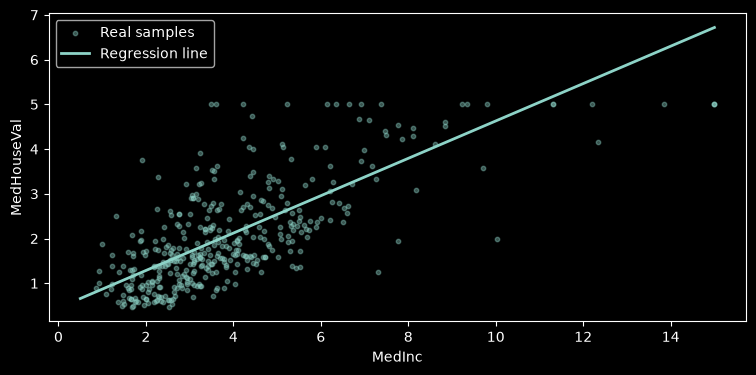

In [63]:
plt.figure(figsize=(9, 4))

# Real data
plt.scatter(x_test[:400], y_test[:400],
            alpha=0.4, s=10, label='Real samples')

# Regression line
xx = np.linspace(x_test.min(), x_test.max(), 150)
plt.plot(xx, w0 + w1 * xx,
         linewidth=2, label='Regression line')

plt.xlabel('MedInc')
plt.ylabel('MedHouseVal')
plt.legend()
plt.show()

---
## 2: Bernoulli and Logistic Regression
Logistic regression models $P(Y=1\mid x)$ using a sigmoid; binary cross-entropy is the Bernoulli negative log-likelihood.

$$p=\sigma(w_0+w_1x),\quad L=-\frac1N\sum_i[y_i\log p_i+(1-y_i)\log(1-p_i)]$$

In [64]:
x = df['MedInc'].to_numpy()
y = (df['MedHouseVal'].to_numpy() > df['MedHouseVal'].median()).astype(int)

In [65]:
y

array([1, 1, 1, ..., 0, 0, 0], shape=(20640,))

In [66]:
df['MedHouseVal'].median()

np.float64(1.797)

In [67]:
df['MedHouseVal']

0        4.526
1        3.585
2        3.521
3        3.413
4        3.422
         ...  
20635    0.781
20636    0.771
20637    0.923
20638    0.847
20639    0.894
Name: MedHouseVal, Length: 20640, dtype: float64

In [68]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=.25, random_state=42)

In [69]:
x_train.shape

(15480,)

In [70]:
x_train.reshape(-1,1)

array([[4.2143],
       [5.3468],
       [3.9191],
       ...,
       [2.9344],
       [5.7192],
       [2.5755]], shape=(15480, 1))

In [71]:
model = LogisticRegression(max_iter=1000)
model.fit(x_train.reshape(-1,1), y_train)
pred_proba = model.predict_proba(x_test.reshape(-1,1))[:,1]
pred_label = (pred_proba >= .5).astype(int)
print('Test accuracy:', round(accuracy_score(y_test,pred_label),3))
print('Test binary cross-entropy:', round(log_loss(y_test,pred_proba),3))
print('First five probabilities:', pred_proba[:5].round(3))

Test accuracy: 0.747
Test binary cross-entropy: 0.502
First five probabilities: [0.115 0.237 0.449 0.891 0.512]


In [72]:
pred_proba = model.predict_proba(x_test.reshape(-1,1))[:,1]
pred_proba

array([0.11544931, 0.23689559, 0.44949743, ..., 0.1763322 , 0.96337506,
       0.95302413], shape=(5160,))

In [73]:
pred_label = (pred_proba >= .5).astype(int)
pred_label

array([0, 0, 0, ..., 0, 1, 1], shape=(5160,))

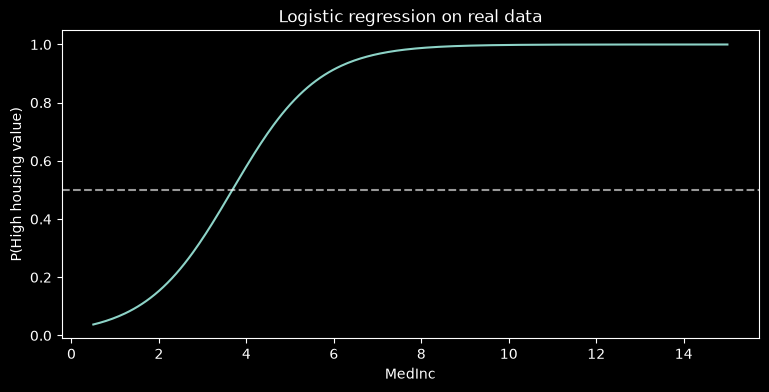

In [74]:
xx = np.linspace(x.min(),x.max(), 300)
plt.figure(figsize=(9,4))
plt.plot(xx, model.predict_proba(xx.reshape(-1,1))[:,1])
plt.axhline(.5, linestyle='--', alpha=.6)
plt.xlabel('MedInc'); plt.ylabel('P(High housing value)'); plt.title('Logistic regression on real data'); plt.show()

---
## 3: Multiclass Classification, Softmax and Categorical Distribution
We now predict the three **derived** housing value groups (`Low`, `Medium`, `High`) using real income measurements. Softmax produces a probability for each category.

In [75]:
df['IncomeGroup'] = pd.qcut(df['MedInc'], q=3, labels=['Low', 'Medium', 'High'])
df['ValueGroup'] = pd.qcut(df['MedHouseVal'], q=3, labels=['Low', 'Medium', 'High'])
counts = pd.crosstab(df['ValueGroup'], df['IncomeGroup'])
N = counts.to_numpy().sum()
print('Observed frequency table:')
display(counts)
print('Total observations:', N)
print('Column totals:'); print(counts.sum(axis=0))
print('Row totals:'); print(counts.sum(axis=1))

Observed frequency table:


IncomeGroup,Low,Medium,High
ValueGroup,,,
Low,4477,2074,333
Medium,1823,3053,2000
High,580,1754,4546


Total observations: 20640
Column totals:
IncomeGroup
Low       6880
Medium    6881
High      6879
dtype: int64
Row totals:
ValueGroup
Low       6884
Medium    6876
High      6880
dtype: int64


Classes: [0 1 2]
First five softmax probability vectors:
 [[0.755 0.212 0.033]
 [0.564 0.341 0.095]
 [0.312 0.446 0.242]
 [0.024 0.268 0.707]
 [0.255 0.454 0.292]]
Each row sums to: [1. 1. 1. 1. 1.]
Test accuracy: 0.585
Multiclass cross-entropy: 0.845


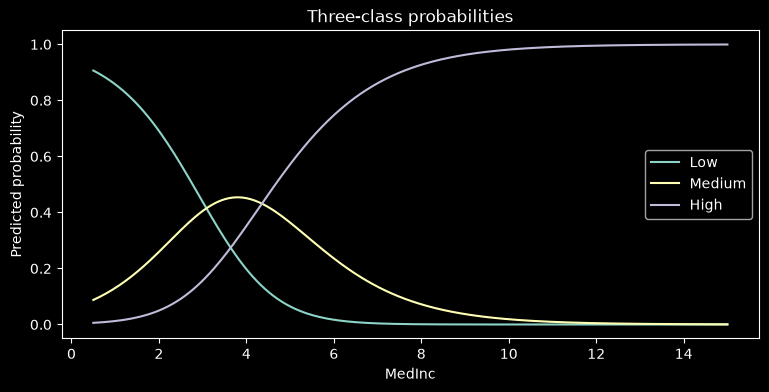

In [76]:
labels = df['ValueGroup'].cat.codes.to_numpy()  # Low=0, Medium=1, High=2
x_multi_train, x_multi_test, y_multi_train, y_multi_test = train_test_split(
    x.reshape(-1,1), labels, test_size=.25, random_state=42)
multi = LogisticRegression(max_iter=1500)
multi.fit(x_multi_train, y_multi_train)
probabilities = multi.predict_proba(x_multi_test)
print('Classes:', multi.classes_)
print('First five softmax probability vectors:\n', probabilities[:5].round(3))
print('Each row sums to:', probabilities[:5].sum(axis=1))
print('Test accuracy:', round(accuracy_score(y_multi_test, multi.predict(x_multi_test)),3))
print('Multiclass cross-entropy:', round(log_loss(y_multi_test, probabilities),3))
xx = np.linspace(x.min(), x.max(), 300).reshape(-1,1)
curves = multi.predict_proba(xx)
plt.figure(figsize=(9,4))
for k, name in enumerate(['Low','Medium','High']):
    plt.plot(xx[:,0], curves[:,k], label=name)
plt.xlabel('MedInc'); plt.ylabel('Predicted probability'); plt.title('Three-class probabilities'); plt.legend(); plt.show()

---
## 4: Two-Layer Neural Network and Backpropagation

### Example 4a: Learn a nonlinear XOR pattern

The lecture's two-layer computation is $z^{[1]}=XW^{[1]}+b^{[1]}$, $a^{[1]}=\tanh(z^{[1]})$, $z^{[2]}=a^{[1]}W^{[2]}+b^{[2]}$, $a^{[2]}=\sigma(z^{[2]})$. Backpropagation passes gradients from the output to the hidden layer. We use a synthetic XOR-style dataset to demonstrate a pattern that a straight line cannot separate.

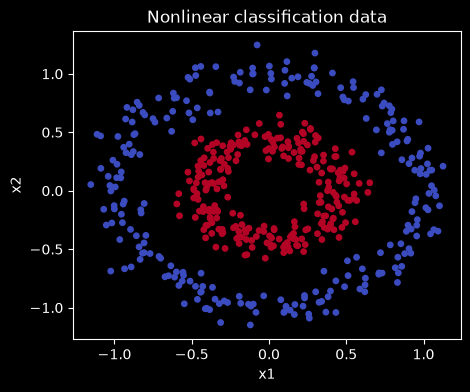

In [77]:
from sklearn.datasets import make_circles
# Generate Circular Dataset
X_nl, y_nl = make_circles(n_samples=500, factor=0.45, noise=0.08, random_state=42)
y_nl = y_nl.reshape(-1, 1).astype(float)
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(X_nl[:, 0], X_nl[:, 1], c=y_nl.ravel(), cmap='coolwarm', s=15)
ax.set(title='Nonlinear classification data', xlabel='x1', ylabel='x2'); plt.show()

In [78]:
import numpy as np

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

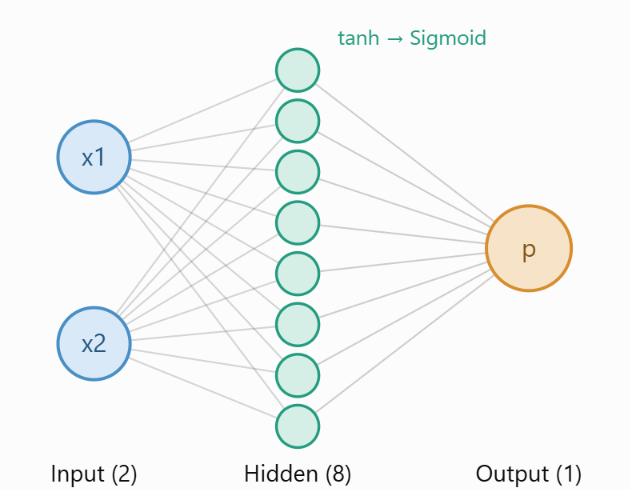

* X	(500, 2)
* y	(500, 1)
* W1	(2, 8)
* b1	(1, 8)
* z1	(500, 8)
* a1	(500, 8)
* W2	(8, 1)
* b2	(1, 1)
* z2	(500, 1)
* a2	(500, 1)

***Binary Cross-Entropy***
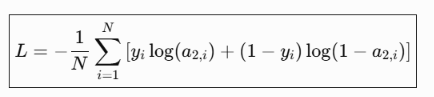

In [79]:
def train_two_layer(X, y, hidden=8, lr=0.5, epochs=2500, seed=42):
    rng = np.random.default_rng(seed)
    W1 = rng.normal(0, 0.5, (X.shape[1], hidden))
    b1 = np.zeros((1, hidden))
    W2 = rng.normal(0, 0.5, (hidden, 1))
    b2 = np.zeros((1, 1))
    losses = []
    for _ in range(epochs):
      # Forward
        z1 = X @ W1 + b1
        a1 = np.tanh(z1)
        z2 = a1 @ W2 + b2
        a2 = sigmoid(z2)
        # Loss
        loss = -np.mean(y*np.log(a2 + 1e-10) +
                        (1-y)*np.log(1-a2 + 1e-10))
        losses.append(loss)
      # Backpropagation
        dz2 = (a2-y)/len(X)
        dW2 = a1.T @ dz2
        db2 = dz2.sum(axis=0, keepdims=True)
        dz1 = (dz2 @ W2.T) * (1-a1**2)
        dW1 = X.T @ dz1
        db1 = dz1.sum(axis=0, keepdims=True)
         # Update
        W1 -= lr*dW1
        b1 -= lr*db1
        W2 -= lr*dW2
        b2 -= lr*db2
    return (W1, b1, W2, b2), np.array(losses)

def predict_two_layer(X, params):
    W1, b1, W2, b2 = params
    return sigmoid(np.tanh(X @ W1 + b1) @ W2 + b2).ravel()

params, nn_losses = train_two_layer(X_nl, y_nl)
print('Neural network accuracy:', accuracy_score(y_nl.ravel(), predict_two_layer(X_nl, params) >= .5))

Neural network accuracy: 1.0


### Task 1: Linear Regression

Using the `Diabetes` dataset from `sklearn.datasets`:

1. Load the dataset.
2. Select one feature to predict the target.
3. Split the data into training and testing sets.
4. Fit a regression line using `np.polyfit()`.
5. Calculate the Mean Squared Error (MSE).
6. Plot the actual values and the regression line.

In [80]:
from sklearn.datasets import load_diabetes


df = load_diabetes(as_frame=True)
df = df.frame
df

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0
...,...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207,178.0
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485,104.0
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491,132.0
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930,220.0


In [81]:
x = df['bmi'].to_numpy()
y = df['target'].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(x.reshape(-1,1), y, test_size=.25, random_state=42)

w1, w0 = np.polyfit(X_train.ravel(), y_train, 1)
pred_train = w0 + w1 * X_train
pred_test = w0 + w1 * X_test

X_test

array([[-0.00620595],
       [ 0.03690653],
       [-0.00405033],
       [ 0.0519959 ],
       [-0.02021751],
       [-0.02452876],
       [ 0.17055523],
       [ 0.04552903],
       [-0.0902753 ],
       [ 0.01535029],
       [-0.03315126],
       [-0.05794093],
       [-0.06117437],
       [ 0.01427248],
       [-0.05578531],
       [ 0.00564998],
       [ 0.07139652],
       [ 0.08864151],
       [ 0.02828403],
       [ 0.05846277],
       [ 0.03906215],
       [-0.04285156],
       [-0.04931844],
       [ 0.02289497],
       [ 0.04445121],
       [ 0.01427248],
       [ 0.05954058],
       [-0.01806189],
       [-0.07410811],
       [-0.02129532],
       [ 0.09295276],
       [-0.0374625 ],
       [ 0.01427248],
       [-0.00620595],
       [ 0.04013997],
       [ 0.07786339],
       [-0.03099563],
       [-0.03315126],
       [-0.03099563],
       [-0.05794093],
       [-0.06979687],
       [-0.02991782],
       [-0.02237314],
       [-0.03315126],
       [-0.04500719],
       [-0

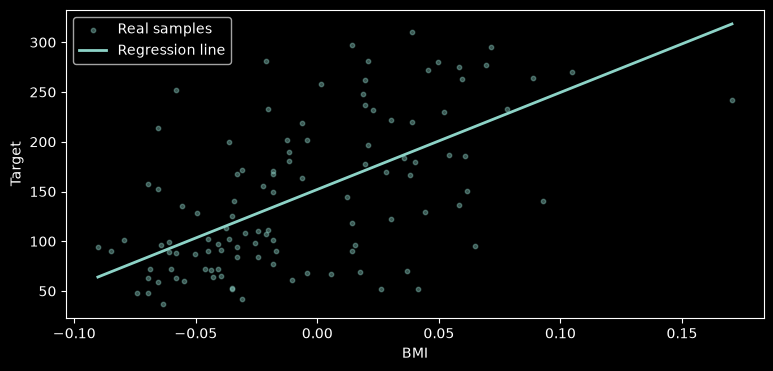

In [82]:
plt.figure(figsize=(9, 4))

plt.scatter(X_test[:400], y_test[:400], alpha=0.4, s=10, label='Real samples')
xx = np.linspace(X_test.min(), X_test.max(), 150)
plt.plot(xx, w0 + w1 * xx, linewidth=2, label='Regression line')
plt.xlabel('BMI')
plt.ylabel('Target')
plt.legend()
plt.show()

### Task 2: Binary Classification

Using the `Breast Cancer` dataset from `sklearn.datasets`:

1. Load the dataset.
2. Select one feature and the target labels.
3. Split the dataset into training and testing sets.
4. Train a `LogisticRegression` model.
5. Calculate the accuracy.
6. Display the first five predicted probabilities.


In [83]:
from sklearn.datasets import load_breast_cancer

df = load_breast_cancer(as_frame=True)
df = df.frame
df

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0


In [84]:
X = df['mean area'].to_numpy()
y = df['target'].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(X.reshape(-1,1), y, test_size=.25, random_state=42)
X_test

array([[ 481.9],
       [1130. ],
       [ 748.9],
       [ 467.8],
       [ 402.9],
       [1265. ],
       [1482. ],
       [ 955.1],
       [ 520. ],
       [ 599.4],
       [ 537.9],
       [ 886.3],
       [ 690.2],
       [ 826.8],
       [ 468.5],
       [1132. ],
       [ 680.7],
       [ 311.7],
       [ 143.5],
       [1308. ],
       [ 584.1],
       [ 446.2],
       [1407. ],
       [ 307.3],
       [ 417.2],
       [ 559.2],
       [ 541.8],
       [ 321.4],
       [ 496.6],
       [ 929.4],
       [ 378.4],
       [ 448.6],
       [ 289.7],
       [ 575.5],
       [ 313.1],
       [ 409. ],
       [ 797.8],
       [ 427.3],
       [1040. ],
       [ 662.7],
       [ 336.1],
       [ 716.6],
       [ 408.2],
       [ 428. ],
       [ 435.6],
       [ 396.5],
       [ 257.8],
       [ 271.3],
       [ 416.2],
       [ 516.6],
       [ 928.3],
       [1088. ],
       [ 529.4],
       [ 594.2],
       [ 432.8],
       [ 537.3],
       [ 324.2],
       [1878. ],
       [ 559.2

In [85]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train.reshape(-1,1), y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [86]:
pred_proba = model.predict_proba(X_test.reshape(-1,1))[:,1]
pred_label = (pred_proba >= .5).astype(int)
print(f'Accuracy: {round(accuracy_score(y_test,pred_label),3)}')
print(f'Top five predicted probabilities: {pred_proba[:5].round(3)}')

Accuracy: 0.909
Top five predicted probabilities: [0.895 0.009 0.333 0.908 0.952]



### Task 3: Multiclass Classification

Using the `Iris` dataset from `sklearn.datasets`:

1. Load the dataset.
2. Select two input features.
3. Train a `LogisticRegression` model to classify the three flower types.
4. Display the predicted probabilities for the first five test samples.
5. Calculate the classification accuracy.

In [87]:
from sklearn.datasets import load_iris

df = load_iris(as_frame=True)
df = df.frame
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [88]:
X = df[['sepal length (cm)', 'sepal width (cm)']].to_numpy()
y = df['target'].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.25, random_state=42)
X_test

array([[6.1, 2.8],
       [5.7, 3.8],
       [7.7, 2.6],
       [6. , 2.9],
       [6.8, 2.8],
       [5.4, 3.4],
       [5.6, 2.9],
       [6.9, 3.1],
       [6.2, 2.2],
       [5.8, 2.7],
       [6.5, 3.2],
       [4.8, 3. ],
       [5.5, 3.5],
       [4.9, 3.1],
       [5.1, 3.8],
       [6.3, 3.3],
       [6.5, 3. ],
       [5.6, 2.5],
       [5.7, 2.8],
       [6.4, 2.8],
       [4.7, 3.2],
       [6.1, 3. ],
       [5. , 3.4],
       [6.4, 2.8],
       [7.9, 3.8],
       [6.7, 3. ],
       [6.7, 2.5],
       [6.8, 3.2],
       [4.8, 3. ],
       [4.8, 3.1],
       [4.6, 3.6],
       [5.7, 4.4],
       [6.7, 3.1],
       [4.8, 3.4],
       [4.4, 3.2],
       [6.3, 2.5],
       [6.4, 3.2],
       [5.2, 3.5]])

In [89]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [90]:
pred_proba = model.predict_proba(X_test)
print(f"Top five predicted probabilities:\n{pred_proba[:5].round(3)}")
pred_label = model.predict(X_test)
print(f"Accuracy: {round(accuracy_score(y_test, pred_label), 3)}")

Top five predicted probabilities:
[[0.024 0.54  0.437]
 [0.711 0.129 0.16 ]
 [0.    0.159 0.841]
 [0.046 0.535 0.419]
 [0.002 0.333 0.665]]
Accuracy: 0.842


### Task 4: Neural Networks

Using `make_moons()` from `sklearn.datasets`:

1. Generate 300 samples.
2. Visualize the dataset using a scatter plot.
3. Create a neural network using `MLPClassifier` with one hidden layer containing 8 neurons.
4. Train the model.
5. Calculate the classification accuracy.
6. Plot the confusion matrix.

In [91]:
from sklearn.datasets import make_moons

df = make_moons(n_samples=300, noise=0.08, random_state=42)
df

(array([[ 6.58800584e-01, -3.55962544e-01],
        [ 1.98630199e+00, -1.33489982e-01],
        [-1.11623440e-01,  4.55081095e-01],
        [ 9.05008164e-01,  2.66798227e-01],
        [ 1.18161893e+00, -4.94965072e-01],
        [ 1.02169091e+00, -4.40272650e-01],
        [ 3.98410830e-01, -2.62658222e-01],
        [-5.81295999e-01,  7.19523934e-01],
        [ 9.20364456e-01,  6.41901790e-02],
        [ 1.92545722e-01,  4.35811566e-03],
        [ 1.31092181e+00, -3.24434582e-01],
        [ 3.79139638e-01,  8.67981117e-01],
        [ 9.47973156e-01, -4.86514560e-01],
        [ 6.52451981e-01,  8.98014619e-01],
        [ 1.42387755e-01, -1.41061929e-02],
        [ 9.98680918e-01, -5.45590675e-01],
        [ 2.00221032e+00,  3.11290196e-01],
        [ 7.21101683e-01, -3.90009423e-01],
        [-8.84789224e-01,  2.16674621e-02],
        [ 1.56067651e-01,  2.68034646e-01],
        [-5.51451464e-02,  1.01137280e+00],
        [-8.17700536e-01,  5.68165642e-01],
        [ 1.50710295e+00, -4.379

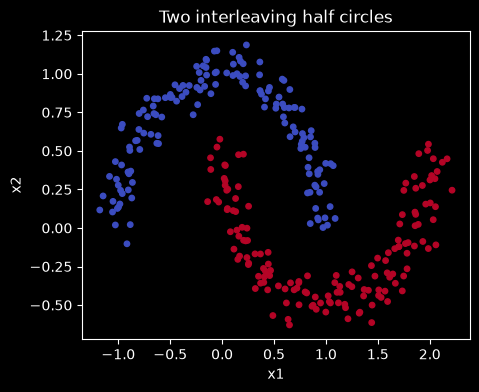

In [92]:
X = df[0]
y = df[1]

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', s=15)
ax.set(title='Two interleaving half circles', xlabel='x1', ylabel='x2')
plt.show()

In [93]:
from sklearn.neural_network import MLPClassifier

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.25, random_state=42)

model = MLPClassifier(hidden_layer_sizes=(8,), activation='tanh', solver='sgd', learning_rate_init=0.5, max_iter=2500, random_state=42)
model.fit(X_train, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(8,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'tanh'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'sgd'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",2500
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [94]:
pred = model.predict(X_test)
print(f'Accuracy: {round(accuracy_score(y_test,pred),3)}')

Accuracy: 1.0


In [95]:
print(f'Confusion Matrix:\n{confusion_matrix(y_test,pred)}')

Confusion Matrix:
[[33  0]
 [ 0 42]]
